# Training the fare model on 2024 trips

Trains the XGBoost model the API serves, on a sample of every month of 2024 NYC yellow-taxi trips.

- **Weather** is hourly Open-Meteo archive data joined on the pickup hour, the same source and units the gateway fetches live, so training and serving see the same kind of input.
- **Route history** (`historical_route_fare`) is a smoothed mean fare per pickup→drop-off pair. Training rows get out-of-fold values (scikit-learn `TargetEncoder`), so no trip's own fare leaks into its feature.
- **Validation** is chronological: the last 20% of the year is the holdout, and hyperparameter search uses `TimeSeriesSplit` on a time-ordered sample.
- **Evaluation** compares against a linear model and the meter formula, and repeats the holdout with *request-time* distance and duration, since a live request only has estimates.

The notebook exports `model.ubj` and `route_means.json` to `service/ml-inference/` and saves its plots to `plots/`. It downloads about 700 MB of trip data and needs roughly 6 GB of RAM at the default sample size.

In [1]:
SAMPLE_FRACTION = 0.25  # share of each month's cleaned trips to keep
RANDOM_STATE = 42
TUNING_SAMPLE = 500_000

In [2]:
import gc
import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import xgboost as xgb
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_absolute_percentage_error, mean_squared_error, r2_score
from sklearn.model_selection import KFold, RandomizedSearchCV, TimeSeriesSplit
from sklearn.preprocessing import TargetEncoder

from taxi_data import SERVICE_DIR, load_hourly_weather, load_trips, load_zones, one_hot_boroughs, save_plot

sns.set_theme(style="whitegrid")

## 1. Load and clean all twelve months

In [3]:
zones, weather = load_zones(), load_hourly_weather()

chunks = []
for month in range(1, 13):
    chunks.append(load_trips(month, zones, weather, sample_fraction=SAMPLE_FRACTION, random_state=RANDOM_STATE))
    print(f"2024-{month:02d}: {len(chunks[-1]):,} trips")
trips = one_hot_boroughs(pd.concat(chunks, ignore_index=True))
del chunks
gc.collect()

trips = trips.sort_values("tpep_pickup_datetime").reset_index(drop=True)
print(f"\n{len(trips):,} trips on {trips.tpep_pickup_datetime.dt.normalize().nunique()} days; "
      f"missing weather: {trips.temp.isna().sum()}")

2024-01: 706,706 trips


2024-02: 714,974 trips


2024-03: 845,825 trips


2024-04: 839,178 trips


2024-05: 888,572 trips


2024-06: 841,740 trips


... (3 outputs left out)

2024-10: 902,470 trips


2024-11: 862,503 trips


2024-12: 863,950 trips



9,754,059 trips on 366 days; missing weather: 0


## 2. Chronological split and route encoding

In [4]:
split = int(len(trips) * 0.8)
train, test = trips.iloc[:split].copy(), trips.iloc[split:].copy()
del trips
gc.collect()
print(f"Train: {len(train):,} trips, {train.tpep_pickup_datetime.min():%b %d} to {train.tpep_pickup_datetime.max():%b %d}")
print(f"Test:  {len(test):,} trips, {test.tpep_pickup_datetime.min():%b %d} to {test.tpep_pickup_datetime.max():%b %d}")

# Out-of-fold means for training rows; the full-training-set means go to the test set and the API.
encoder = TargetEncoder(target_type="continuous", smooth=50.0,
                        cv=KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE))
train["historical_route_fare"] = encoder.fit_transform(train[["route_id"]], train.fare_amount).ravel().astype("float32")
test["historical_route_fare"] = encoder.transform(test[["route_id"]]).ravel().astype("float32")
route_means = {str(int(r)): round(float(v), 2) for r, v in zip(encoder.categories_[0], encoder.encodings_[0])}
print(f"{len(route_means):,} routes encoded")

Train: 7,803,247 trips, Jan 01 to Oct 24
Test:  1,950,812 trips, Oct 24 to Dec 31


37,209 routes encoded


In [5]:
BOROUGHS = sorted(zones.Borough.unique())
FEATURES = (
    ["trip_miles", "trip_time", "request_hour", "is_weekend", "is_airport_trip",
     "temp", "precip", "snow", "implied_speed_mph"]
    + [f"PU_Borough_{b}" for b in BOROUGHS]
    + [f"DO_Borough_{b}" for b in BOROUGHS]
    + ["historical_route_fare"]
)
X_train, y_train = train[FEATURES], train.fare_amount
X_test, y_test = test[FEATURES], test.fare_amount
print(len(FEATURES), "features")

22 features


## 3. Hyperparameter search, then the final fit

The search runs on a 500K-trip sample kept in time order, so each `TimeSeriesSplit` fold validates on trips that come after its training trips.

In [6]:
rng = np.random.default_rng(RANDOM_STATE)
idx = np.sort(rng.choice(len(X_train), size=min(TUNING_SAMPLE, len(X_train)), replace=False))

search = RandomizedSearchCV(
    xgb.XGBRegressor(tree_method="hist", random_state=RANDOM_STATE, n_jobs=-1),
    param_distributions={
        "n_estimators": [200, 300, 400],
        "learning_rate": [0.03, 0.05, 0.1],
        "max_depth": [6, 8, 10],
        "subsample": [0.7, 0.8, 0.9],
        "colsample_bytree": [0.7, 0.8, 0.9],
    },
    n_iter=10, scoring="neg_mean_absolute_error", cv=TimeSeriesSplit(n_splits=3),
    random_state=RANDOM_STATE, n_jobs=1,
)
search.fit(X_train.iloc[idx], y_train.iloc[idx])
best_params = search.best_params_
print("Best parameters:", best_params, f"(CV MAE ${-search.best_score_:.2f})")

Best parameters: {'subsample': 0.9, 'n_estimators': 300, 'max_depth': 6, 'learning_rate': 0.05, 'colsample_bytree': 0.8} (CV MAE $1.12)


In [7]:
model = xgb.XGBRegressor(**best_params, tree_method="hist", random_state=RANDOM_STATE, n_jobs=-1)
model.fit(X_train, y_train)
pred = model.predict(X_test)
print(f"Trained on {len(X_train):,} trips")

Trained on 7,803,247 trips


## 4. Holdout results

The baselines get the same recorded distance and duration as the model. The last two rows score XGBoost on the same trips twice: once with recorded inputs, once with **request-time estimates**, where each trip's distance and duration are replaced by the training-set median for its route and 3-hour time-of-day bucket (falling back to the route median). Trips on routes never seen in training are left out of those two rows.

In [8]:
results = []

def score(name, y_true, y_pred):
    results.append({
        "Method": name,
        "Trips": len(y_true),
        "MAE ($)": round(mean_absolute_error(y_true, y_pred), 2),
        "RMSE ($)": round(float(np.sqrt(mean_squared_error(y_true, y_pred))), 2),
        "MAPE (%)": round(100 * mean_absolute_percentage_error(y_true, y_pred), 1),
        "R²": round(r2_score(y_true, y_pred), 3),
    })

score("XGBoost", y_test, pred)

linear_cols = ["trip_miles", "trip_time", "is_airport_trip"]
linear = LinearRegression().fit(train[linear_cols], y_train)
linear_pred = linear.predict(test[linear_cols])
score("Linear regression (miles, seconds, airport flag)", y_test, linear_pred)

meter_pred = 3.0 + 0.7 * np.maximum(5 * test.trip_miles, test.trip_time / 60)
score("Meter formula: 3 + 0.70 × max(5 × miles, minutes)", y_test, meter_pred)

# Request-time estimates from training medians
train["bucket"] = train.request_hour // 3
test["bucket"] = test.request_hour // 3
by_route_bucket = train.groupby(["route_id", "bucket"])[["trip_miles", "trip_time"]].median()
by_route = train.groupby("route_id")[["trip_miles", "trip_time"]].median()
estimate = test[["route_id", "bucket"]].join(by_route_bucket, on=["route_id", "bucket"])
fallback = test[["route_id"]].join(by_route, on="route_id")
for col in ["trip_miles", "trip_time"]:
    estimate[col] = estimate[col].fillna(fallback[col])
covered = estimate.trip_miles.notna().to_numpy()

X_estimated = X_test[covered].copy()
X_estimated["trip_miles"] = estimate.loc[covered, "trip_miles"].astype("float32")
X_estimated["trip_time"] = estimate.loc[covered, "trip_time"].astype("float32")
X_estimated["implied_speed_mph"] = (X_estimated.trip_miles / X_estimated.trip_time * 3600).clip(0, 75)
print(f"Request-time estimates available for {covered.mean():.1%} of test trips")
score("XGBoost, recorded inputs (same trips)", y_test[covered], pred[covered])
score("XGBoost, request-time estimates", y_test[covered], model.predict(X_estimated))

summary = pd.DataFrame(results)
summary

Request-time estimates available for 99.9% of test trips


,Method,Trips,MAE ($),RMSE ($),MAPE (%),R²
0,XGBoost,1950812,1.13,3.29,6.3,0.959
1,"Linear regression (miles, seconds, airport flag)",1950812,2.22,4.72,12.7,0.916
2,"Meter formula: 3 + 0.70 × max(5 × miles, minutes)",1950812,2.57,5.38,11.3,0.891
3,"XGBoost, recorded inputs (same trips)",1948134,1.12,3.26,6.2,0.960
4,"XGBoost, request-time estimates",1948134,3.32,5.59,19.9,0.882


With recorded inputs, XGBoost halves the linear baseline's error ($1.13 against $2.22 MAE) and beats the meter formula by more than half.

With request-time estimates, the same model's MAE roughly triples, to $3.32, which is worse than the baselines on recorded inputs. So at request time, most of the remaining error comes from not knowing the trip's real distance and duration, not from the model. A route median ignores that day's traffic. The live API uses Google's traffic-aware route when a key is set; that should land between these two rows, but it isn't measured here.

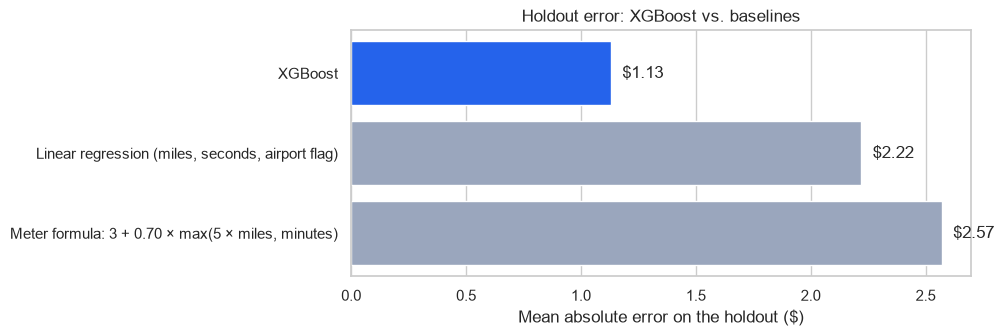

In [9]:
fig, ax = plt.subplots(figsize=(8, 3.2))
main_rows = summary.iloc[:3].iloc[::-1]
ax.barh(main_rows.Method, main_rows["MAE ($)"], color=["#9aa6bd", "#9aa6bd", "#2563eb"])
for y, value in enumerate(main_rows["MAE ($)"]):
    ax.text(value + 0.05, y, f"${value:.2f}", va="center")
ax.set_xlabel("Mean absolute error on the holdout ($)")
ax.set_title("Holdout error: XGBoost vs. baselines")
ax.grid(axis="y", visible=False)
save_plot(fig, "model_comparison")
plt.show()

### Where the errors are

,XGBoost,Linear,Meter formula,share of trips
fare range,,,,
< $10,0.52,1.42,0.62,29.4%
$10–20,0.71,1.08,1.51,39.6%
$20–30,1.42,2.75,3.46,14.6%
$30–50,2.29,4.15,6.00,9.7%
$50–75,2.78,7.06,8.69,5.7%
$75+,11.66,18.81,22.51,0.9%


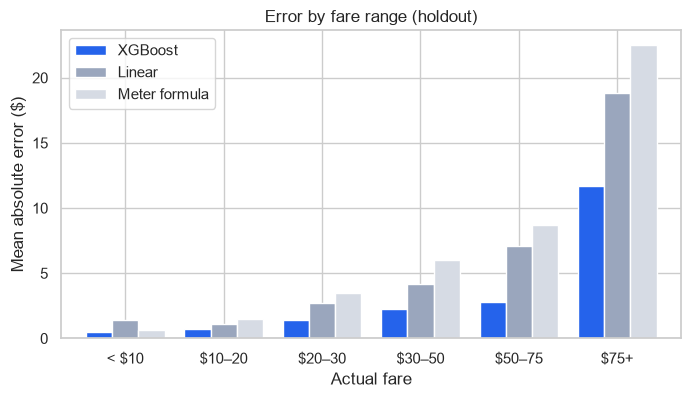

In [10]:
bins = [0, 10, 20, 30, 50, 75, 400]
labels = ["< $10", "$10–20", "$20–30", "$30–50", "$50–75", "$75+"]
by_range = pd.DataFrame({
    "fare range": pd.cut(y_test, bins=bins, labels=labels),
    "XGBoost": np.abs(pred - y_test),
    "Linear": np.abs(linear_pred - y_test),
    "Meter formula": np.abs(meter_pred - y_test),
}).groupby("fare range", observed=True).mean().astype(float)
share = pd.cut(y_test, bins=bins, labels=labels).value_counts(normalize=True).reindex(labels)
display(by_range.round(2).assign(**{"share of trips": (100 * share).round(1).astype(str) + "%"}))

fig, ax = plt.subplots(figsize=(8, 4))
by_range.plot.bar(ax=ax, color=["#2563eb", "#9aa6bd", "#d6dbe4"], rot=0, width=0.8)
ax.set_xlabel("Actual fare")
ax.set_ylabel("Mean absolute error ($)")
ax.set_title("Error by fare range (holdout)")
save_plot(fig, "error_by_fare_range")
plt.show()

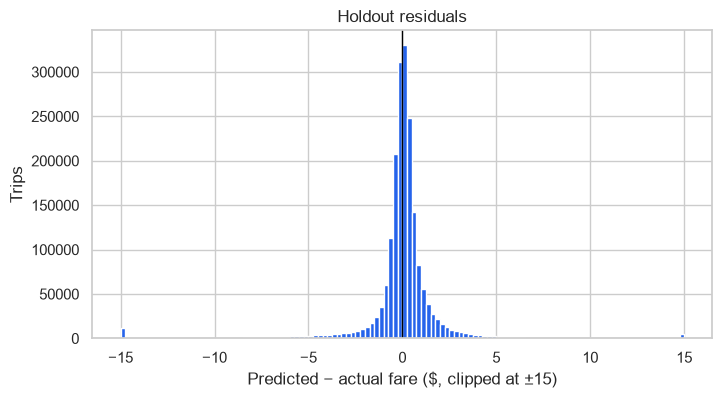

Within $1: 76.6%   within $5: 96.1%


In [11]:
residuals = pred - y_test
fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(residuals.clip(-15, 15), bins=120, color="#2563eb")
ax.axvline(0, color="black", linewidth=1)
ax.set_xlabel("Predicted − actual fare ($, clipped at ±15)")
ax.set_ylabel("Trips")
ax.set_title("Holdout residuals")
save_plot(fig, "residuals")
plt.show()
within_1 = (np.abs(residuals) <= 1).mean()
within_5 = (np.abs(residuals) <= 5).mean()
print(f"Within $1: {within_1:.1%}   within $5: {within_5:.1%}")

About three quarters of holdout fares come within $1 of the prediction. The large errors are concentrated in the under-1% of trips above $75, mostly long airport and out-of-city rides, where negotiated fares and unusual routes are common.

Distance dominates the importance ranking, followed by duration and the route's fare history. Weather and hour add almost nothing once distance and duration are known: their effect on the fare already shows up in a slower, longer trip.

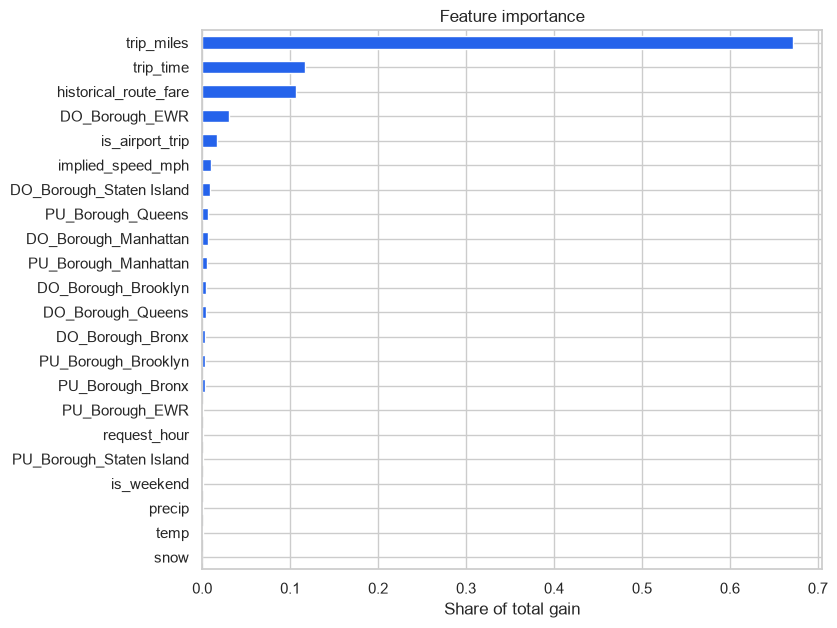

In [12]:
importance = pd.Series(model.get_booster().get_score(importance_type="gain")).reindex(FEATURES).fillna(0)
importance = (importance / importance.sum()).sort_values()
fig, ax = plt.subplots(figsize=(8, 7))
importance.plot.barh(ax=ax, color="#2563eb")
ax.set_xlabel("Share of total gain")
ax.set_title("Feature importance")
save_plot(fig, "feature_importance")
plt.show()

## 5. Export for the API

In [13]:
model_path = SERVICE_DIR / "model.ubj"
model.save_model(model_path)
(SERVICE_DIR / "route_means.json").write_text(json.dumps(route_means))
print(f"Saved {model_path.name} ({model_path.stat().st_size / 1e6:.1f} MB) and route_means.json ({len(route_means):,} routes)")

xgb_mae = summary.loc[summary.Method == "XGBoost", "MAE ($)"].item()
linear_mae = summary.loc[summary.Method.str.startswith("Linear"), "MAE ($)"].item()
print(f"XGBoost cuts holdout MAE by {1 - xgb_mae / linear_mae:.0%} against the linear baseline.\n")
print(summary.to_markdown(index=False))

Saved model.ubj (1.4 MB) and route_means.json (37,209 routes)
XGBoost cuts holdout MAE by 49% against the linear baseline.

| Method                                            |   Trips |   MAE ($) |   RMSE ($) |   MAPE (%) |    R² |
|:--------------------------------------------------|--------:|----------:|-----------:|-----------:|------:|
| XGBoost                                           | 1950812 |      1.13 |       3.29 |        6.3 | 0.959 |
| Linear regression (miles, seconds, airport flag)  | 1950812 |      2.22 |       4.72 |       12.7 | 0.916 |
| Meter formula: 3 + 0.70 × max(5 × miles, minutes) | 1950812 |      2.57 |       5.38 |       11.3 | 0.891 |
| XGBoost, recorded inputs (same trips)             | 1948134 |      1.12 |       3.26 |        6.2 | 0.96  |
| XGBoost, request-time estimates                   | 1948134 |      3.32 |       5.59 |       19.9 | 0.882 |
